# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [18]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [ ]:

# Loading the cleaned aviation accident dataset
df = pd.read_csv('aviation_accidents_cleaned.csv')

# Confirming that the data has loaded successfully
print("Cleaned aviation accident data loaded successfully!")

# Displaying the dataset dimensions
print("Number of rows and columns:", df.shape)

# Previewing the first five records
display(df.head())

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_4092\3510060332.py:2: DtypeWarning: Columns (0: Latitude, 1: Longitude, 2: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('aviation_accidents_cleaned.csv')


Cleaned aviation accident data loaded successfully!
Number of rows and columns: (54204, 33)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Fatal.Serious.Fraction,Aircraft.Destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,1,3,VMC,Approach,Probable Cause,NaN,4,0.0,False,CESSNA.182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,0,2,VMC,Landing,Probable Cause,NaN,2,0.0,False,CESSNA.182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,0,1,VMC,Takeoff,Probable Cause,NaN,1,0.0,False,CESSNA.182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,2,0,VMC,Approach,Probable Cause,NaN,2,0.0,False,PIPER.PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,0,2,VMC,Landing,Probable Cause,NaN,2,0.0,False,CESSNA.140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [ ]:
# Inspecting the passenger count column before separating aircraft
print(df['Total.Passengers'].describe())

# Checking how many passenger counts are missing
print("Missing passenger counts:", df['Total.Passengers'].isna().sum())

# Setting the passenger threshold specified by the client
passenger_threshold = 20

# Separating smaller airplanes (20 passengers or fewer)
small_airplanes = df[
    df['Total.Passengers'].notna() &
    (df['Total.Passengers'] <= passenger_threshold)
].copy()

# Separating larger airplanes (more than 20 passengers)
large_airplanes = df[
    df['Total.Passengers'].notna() &
    (df['Total.Passengers'] > passenger_threshold)
].copy()

# Displaying the number of records in each group
print("Smaller airplane records:", len(small_airplanes))
print("Larger airplane records:", len(large_airplanes))

# Checking the passenger counts in each group
print("Smaller airplanes:")
display(small_airplanes['Total.Passengers'].describe())

print("\nLarger airplanes:")
display(large_airplanes['Total.Passengers'].describe())

count    54204.000000
mean         3.163475
std         14.750657
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max        573.000000
Name: Total.Passengers, dtype: float64
Missing passenger counts: 0
Smaller airplane records: 53726
Larger airplane records: 478
Smaller airplanes:


count    53726.000000
mean         2.009232
std          1.467789
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max         20.000000
Name: Total.Passengers, dtype: float64


Larger airplanes:


count    478.000000
mean     132.897490
std       86.403689
min       21.000000
25%       71.000000
50%      120.500000
75%      170.000000
max      573.000000
Name: Total.Passengers, dtype: float64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

15 makes with the lowest mean injury fraction: Smaller airplanes


,Mean Fatal/Serious Injury Fraction
Make,
GRUMMAN-SCHWEIZER,0.098916
WACO,0.130159
SCHWEIZER,0.135714
GREAT LAKES,0.141509
MAULE,0.159529
AVIAT AIRCRAFT INC,0.164474
HELIO,0.175096
GRUMMAN,0.182204
BOEING,0.187289


15 makes with the lowest mean injury fraction: Larger airplanes


,Mean Fatal/Serious Injury Fraction
Make,
AERO COMMANDER,0.000000
SWEARINGEN,0.000000
CESSNA,0.008150
MCDONNELL DOUGLAS,0.052785
LEARJET,0.130435
EMBRAER,0.134317
BOEING,0.200363
DOUGLAS,0.241333
DE HAVILLAND,0.247824


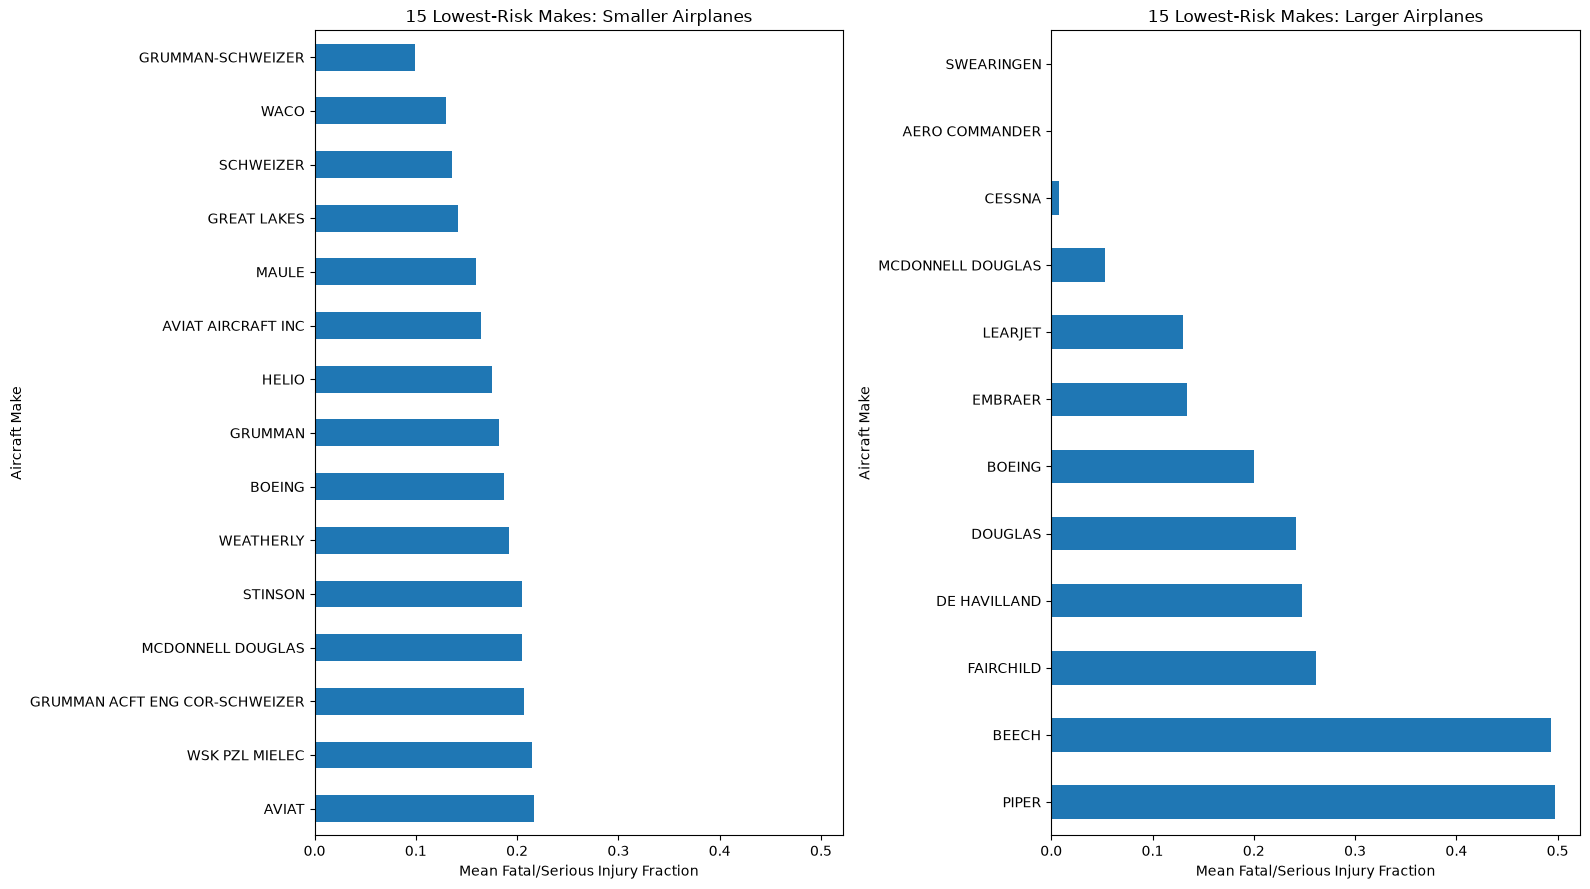

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculating the mean fatal/seriously injured fraction for each make
small_make_risk = (
    small_airplanes
    .dropna(subset=['Make', 'Fatal.Serious.Fraction'])
    .groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .sort_values()
    .head(15)
)

large_make_risk = (
    large_airplanes
    .dropna(subset=['Make', 'Fatal.Serious.Fraction'])
    .groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .sort_values()
    .head(15)
)

# Displaying the selected makes and their mean injury fractions
print("15 makes with the lowest mean injury fraction: Smaller airplanes")
display(small_make_risk.to_frame('Mean Fatal/Serious Injury Fraction'))

print("15 makes with the lowest mean injury fraction: Larger airplanes")
display(large_make_risk.to_frame('Mean Fatal/Serious Injury Fraction'))

# Creating two plots using the same horizontal scale
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True)

# Ploting smaller airplanes
small_make_risk.sort_values(ascending=False).plot(
    kind='barh',
    ax=axes[0]
)

axes[0].set_title('15 Lowest-Risk Makes: Smaller Airplanes')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[0].set_ylabel('Aircraft Make')

# Ploting larger airplanes
large_make_risk.sort_values(ascending=False).plot(
    kind='barh',
    ax=axes[1]
)

axes[1].set_title('15 Lowest-Risk Makes: Larger Airplanes')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[1].set_ylabel('Aircraft Make')

# Improving spacing and readability
plt.tight_layout()
plt.show()

## Interpret the results
- Lower values indicate a lower average fatal/serious injury fraction in the recorded accidents.
- Compare the two plots to see which makes appear among the lowest-risk groups for each aircraft size category.
- These results describe injury outcomes in the accident records, not the overall probability of an aircraft having an accident.
Important assumption: A make with very few recorded accidents may appear to have a low mean simply because its sample is small. Before making final recommendations, it is worth checking the number of accident records behind each make's average.

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

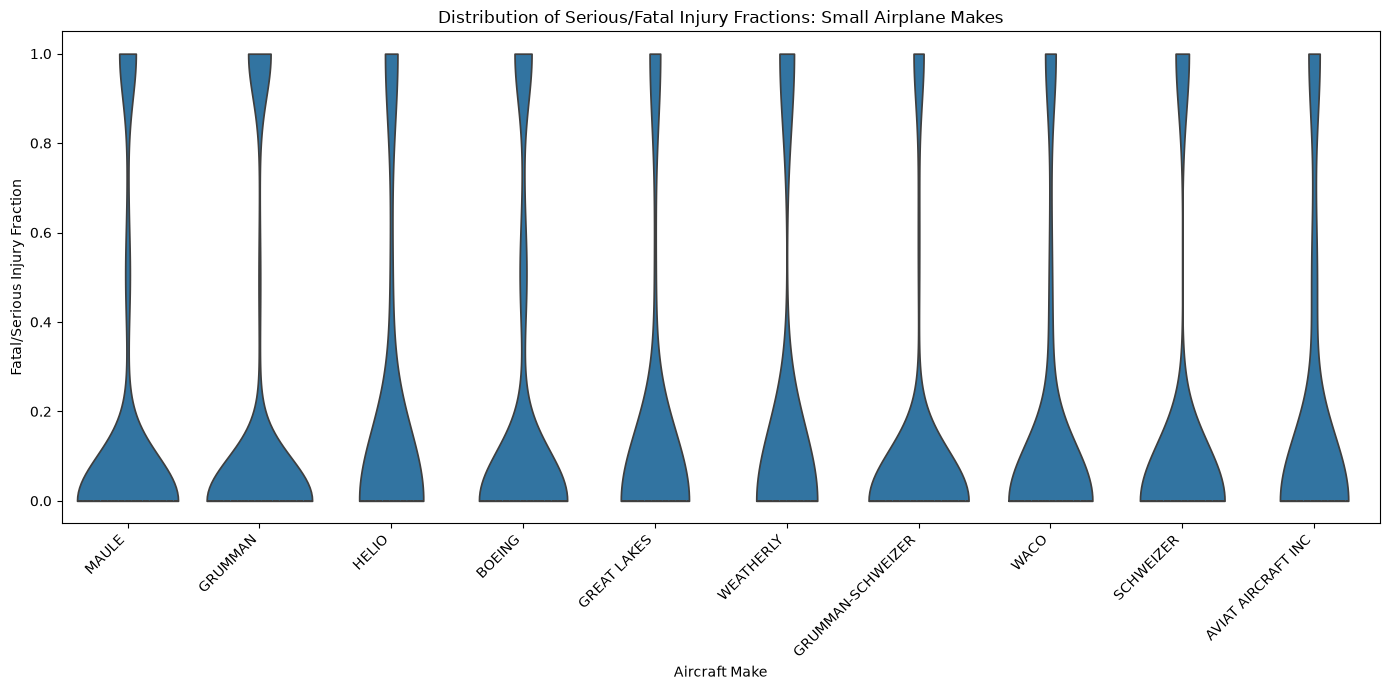

In [ ]:
# Finding the 10 makes with the lowest mean serious/fatal injury fraction
top_10_small_makes = (
    small_airplanes
    .dropna(subset=['Make', 'Fatal.Serious.Fraction'])
    .groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .nsmallest(10)
    .index
)

# Keeping all available accident records for the selected makes
small_makes_data = small_airplanes[
    small_airplanes['Make'].isin(top_10_small_makes)
].dropna(subset=['Fatal.Serious.Fraction']).copy()


import matplotlib.pyplot as plt
import seaborn as sns

# Ploting the distribution of injury fractions for the selected makes
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=small_makes_data,
    x='Make',
    y='Fatal.Serious.Fraction',
    inner='quartile',
    cut=0
)

plt.title('Distribution of Serious/Fatal Injury Fractions: Small Airplane Makes')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

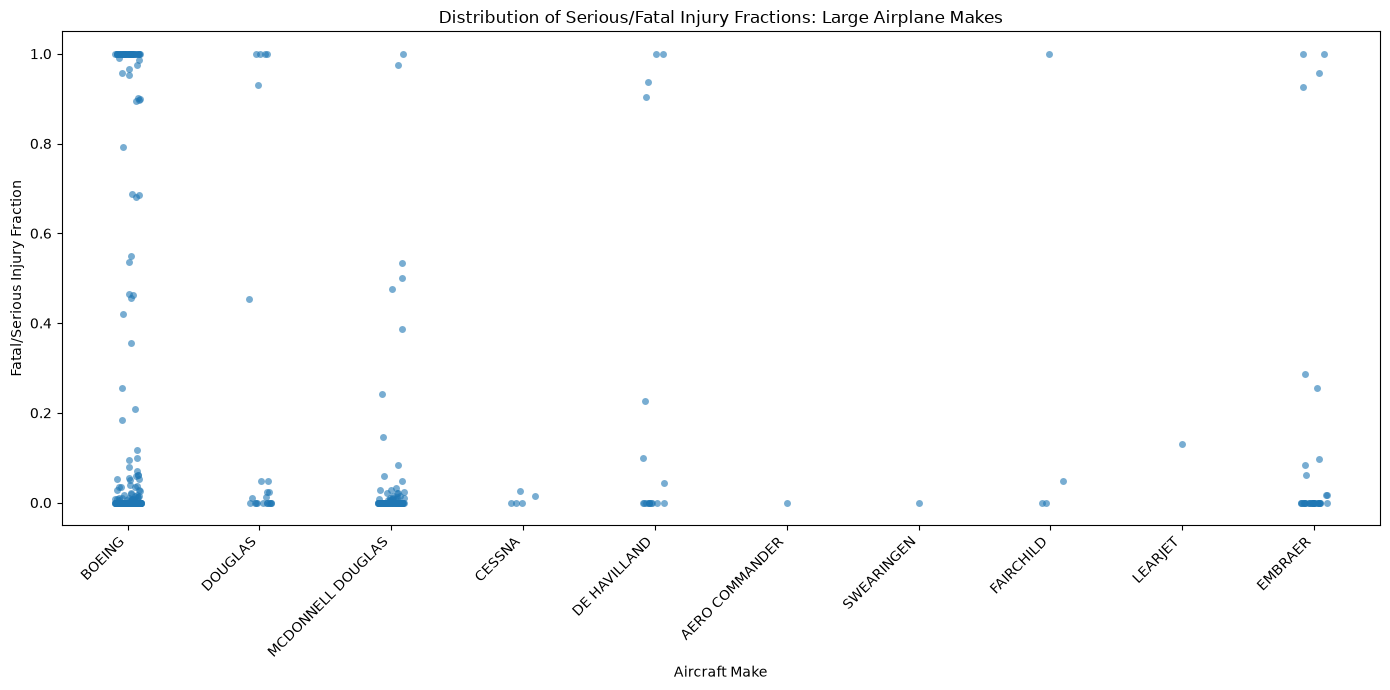

In [ ]:
# Selecting the 10 large-airplane makes with the lowest mean injury fraction
top_10_large_makes = (
    large_airplanes
    .dropna(subset=['Make', 'Fatal.Serious.Fraction'])
    .groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .nsmallest(10)
    .index
)

# Filtering the data 
large_makes_data = large_airplanes[
    large_airplanes['Make'].isin(top_10_large_makes)
].dropna(subset=['Fatal.Serious.Fraction']).copy()

import matplotlib.pyplot as plt
import seaborn as sns

# Displaying the distribution of injury fractions for the selected makes
plt.figure(figsize=(14, 7))

sns.stripplot(
    data=large_makes_data,
    x='Make',
    y='Fatal.Serious.Fraction',
    jitter=True,
    alpha=0.6
)

plt.title('Distribution of Serious/Fatal Injury Fractions: Large Airplane Makes')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [ ]:
# Calculating aircraft destruction rates for small airplanes
small_destruction_rates = (
    small_airplanes
    .dropna(subset=['Make', 'Aircraft.Destroyed'])
    .groupby('Make')['Aircraft.Destroyed']
    .mean()
    .sort_values()
    .head(15)
)

# Calculating aircraft destruction rates for large airplanes
large_destruction_rates = (
    large_airplanes
    .dropna(subset=['Make', 'Aircraft.Destroyed'])
    .groupby('Make')['Aircraft.Destroyed']
    .mean()
    .sort_values()
    .head(15)
)

# Displaying the 15 makes with the lowest destruction rates
print("15 makes with the lowest destruction rates: Small airplanes")
display(small_destruction_rates.to_frame('Destruction Rate'))

print("15 makes with the lowest destruction rates: Large airplanes")
display(large_destruction_rates.to_frame('Destruction Rate'))

# Converting the destruction rates to percentages
small_destruction_percent = (small_destruction_rates * 100).round(2)
large_destruction_percent = (large_destruction_rates * 100).round(2)

print("Small airplanes: Destruction rates (%)")
display(small_destruction_percent.to_frame('Destruction Rate (%)'))

print("Large airplanes: Destruction rates (%)")
display(large_destruction_percent.to_frame('Destruction Rate (%)'))

print(df['Aircraft.damage'].value_counts(dropna=False))

15 makes with the lowest destruction rates: Small airplanes


,Destruction Rate
Make,
GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241
AMERICAN CHAMPION AIRCRAFT,0.037736
AVIAT AIRCRAFT INC,0.039474
DEHAVILLAND,0.042553
DIAMOND AIRCRAFT IND INC,0.055556
AVIAT,0.089552
MAULE,0.090909
ERCOUPE,0.095890
LUSCOMBE,0.101648


15 makes with the lowest destruction rates: Large airplanes


,Destruction Rate
Make,
AERO COMMANDER,0.000000
SWEARINGEN,0.000000
EMBRAER,0.114286
MCDONNELL DOUGLAS,0.122222
CESSNA,0.200000
BOEING,0.219178
DE HAVILLAND,0.294118
DOUGLAS,0.347826
FAIRCHILD,0.500000


Small airplanes: Destruction rates (%)


,Destruction Rate (%)
Make,
GRUMMAN ACFT ENG COR-SCHWEIZER,1.72
AMERICAN CHAMPION AIRCRAFT,3.77
AVIAT AIRCRAFT INC,3.95
DEHAVILLAND,4.26
DIAMOND AIRCRAFT IND INC,5.56
AVIAT,8.96
MAULE,9.09
ERCOUPE,9.59
LUSCOMBE,10.16


Large airplanes: Destruction rates (%)


,Destruction Rate (%)
Make,
AERO COMMANDER,0.00
SWEARINGEN,0.00
EMBRAER,11.43
MCDONNELL DOUGLAS,12.22
CESSNA,20.00
BOEING,21.92
DE HAVILLAND,29.41
DOUGLAS,34.78
FAIRCHILD,50.00


Aircraft.damage
Substantial    42410
Destroyed      11433
Minor            361
Name: count, dtype: int64


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

## Discussion and Recommendations

The analysis compared aircraft makes for smaller airplanes (20 passengers or fewer) and larger airplanes (more than 20 passengers), focusing on aircraft destruction rates and the fraction of passengers fatally or seriously injured.

The makes with the lowest destruction rates may be worth further investigation, particularly when they also have low mean fatal/serious injury fractions. However, a low destruction rate does not necessarily mean that an aircraft is safer for passengers. An aircraft may sustain limited damage while passengers experience serious injuries, or it may be destroyed without resulting in severe injuries.

The violin plot for small-airplane makes showed the distribution and concentration of injury fractions, while the strip plot for large-airplane makes showed individual accident outcomes and their variation. These distributions help reveal whether a low average reflects consistently low injury fractions or is influenced by a small number of observations. The summary statistics should therefore be considered alongside the number of accident records for each make.

**Recommendations:** Prioritize makes that demonstrate both low destruction rates and low fatal/serious injury fractions for further evaluation. Assess smaller and larger airplanes separately, and consider the number of observations behind each result before making recommendations. Because this analysis uses accident records rather than total flight hours or aircraft usage, the findings cannot establish the overall probability of an accident for each make. Additional operational and exposure data would be needed before making definitive safety recommendations.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Records after filtering: 98
Makes included: 2
Make-model combinations included: 4


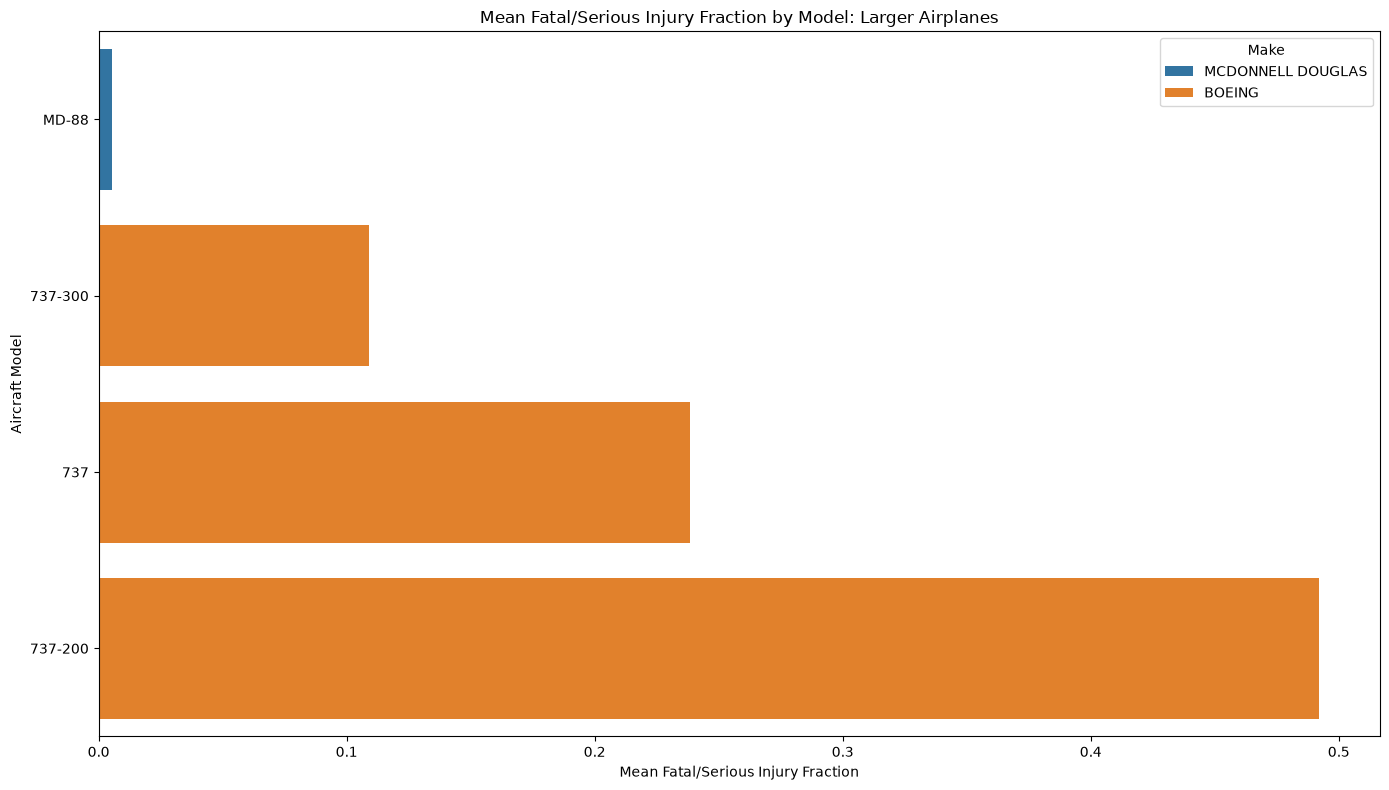

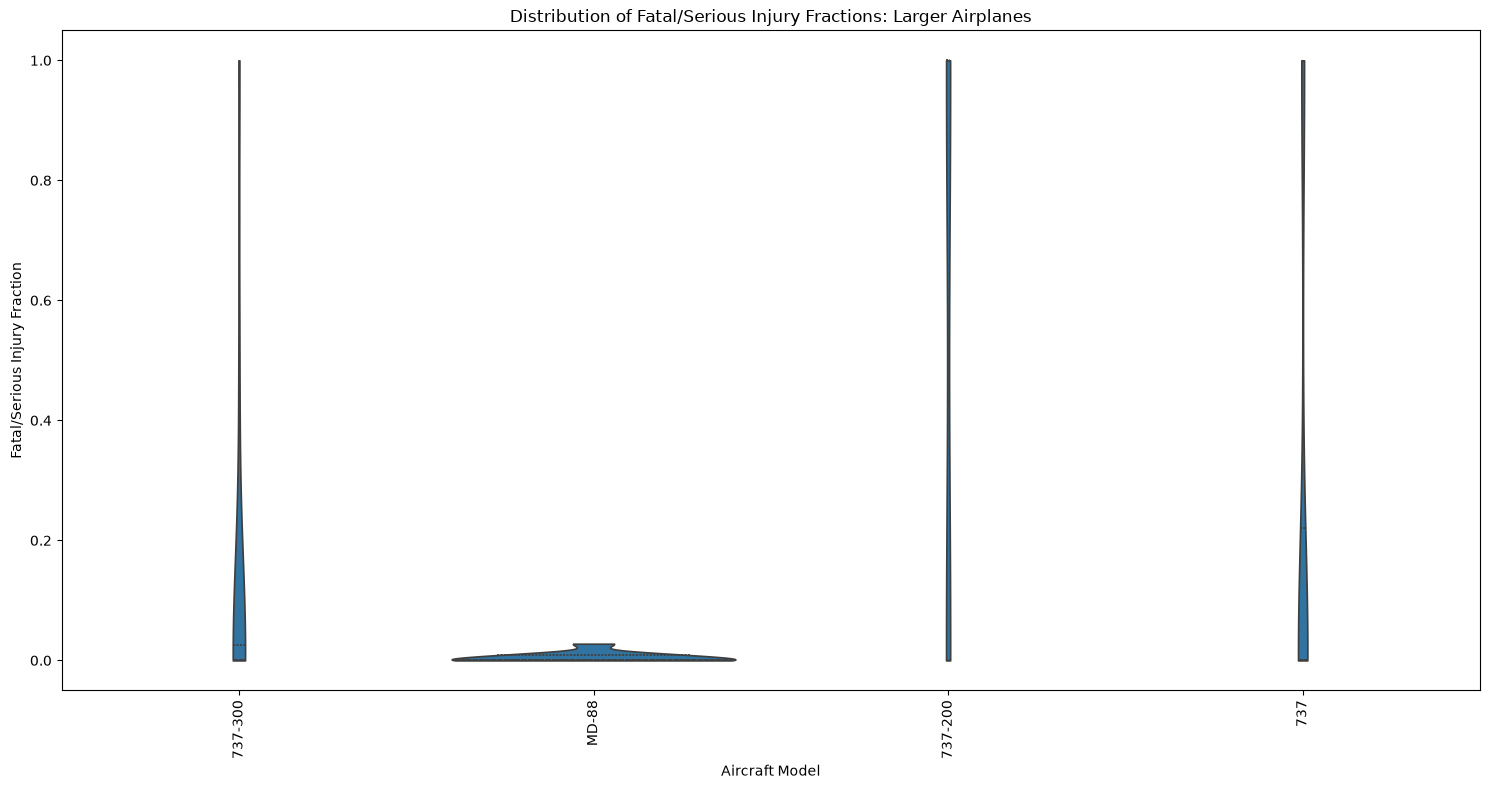

Accident Records  Mean Injury Fraction  \
Make              Model                                             
MCDONNELL DOUGLAS MD-88                  10              0.005520   
BOEING            737-300                15              0.109169   
                  737                    55              0.238493   
                  737-200                18              0.492025   

                           Median Injury Fraction  Standard Deviation  
Make              Model                                                
MCDONNELL DOUGLAS MD-88                  0.000000            0.008933  
BOEING            737-300                0.000000            0.273792  
                  737                    0.000000            0.407413  
                  737-200                0.431334            0.499815

In [ ]:

# Keeping records with valid make, model, and injury fraction
large_valid = large_airplanes.dropna(
    subset=['Make', 'Model', 'Fatal.Serious.Fraction']
).copy()

# Keeping only makes with at least 10 accident records
large_make_counts = large_valid['Make'].value_counts()
valid_large_makes = large_make_counts[large_make_counts >= 10].index

large_valid = large_valid[
    large_valid['Make'].isin(valid_large_makes)
].copy()

# Keeping only models with at least 10 accident records
large_model_counts = large_valid.groupby(
    ['Make', 'Model']
).size()

valid_large_models = large_model_counts[
    large_model_counts >= 10
].index

large_valid = large_valid.set_index(['Make', 'Model']).loc[
    lambda x: x.index.isin(valid_large_models)
].reset_index()

print("Records after filtering:", len(large_valid))
print("Makes included:", large_valid['Make'].nunique())
print("Make-model combinations included:",
      large_valid.groupby(['Make', 'Model']).ngroups)

# Calculating mean injury fraction for each make-model combination
large_model_means = (
    large_valid
    .groupby(['Make', 'Model'])['Fatal.Serious.Fraction']
    .mean()
    .reset_index()
    .sort_values('Fatal.Serious.Fraction')
)

# Ploting the mean injury fractions
plt.figure(figsize=(14, 8))

sns.barplot(
    data=large_model_means,
    x='Fatal.Serious.Fraction',
    y='Model',
    hue='Make',
    dodge=False
)

plt.title('Mean Fatal/Serious Injury Fraction by Model: Larger Airplanes')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Aircraft Model')
plt.tight_layout()
plt.show()

# Displaying the distribution for the qualifying large-airplane models
plt.figure(figsize=(15, 8))

sns.violinplot(
    data=large_valid,
    x='Model',
    y='Fatal.Serious.Fraction',
    inner='quartile',
    cut=0
)

plt.title('Distribution of Fatal/Serious Injury Fractions: Larger Airplanes')
plt.xlabel('Aircraft Model')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Showing accident counts and mean injury fractions for each make-model combination
large_model_summary = (
    large_valid
    .groupby(['Make', 'Model'])['Fatal.Serious.Fraction']
    .agg(['count', 'mean', 'median', 'std'])
    .sort_values('mean')
    .rename(columns={
        'count': 'Accident Records',
        'mean': 'Mean Injury Fraction',
        'median': 'Median Injury Fraction',
        'std': 'Standard Deviation'
    })
)

display(large_model_summary)

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

Selected makes:


,count,mean
Make,,
GRUMMAN-SCHWEIZER,123,0.098916
WACO,105,0.130159
SCHWEIZER,140,0.135714
GREAT LAKES,53,0.141509
MAULE,495,0.159529
AVIAT AIRCRAFT INC,76,0.164474
HELIO,71,0.175096
GRUMMAN,976,0.182204
BOEING,409,0.187289


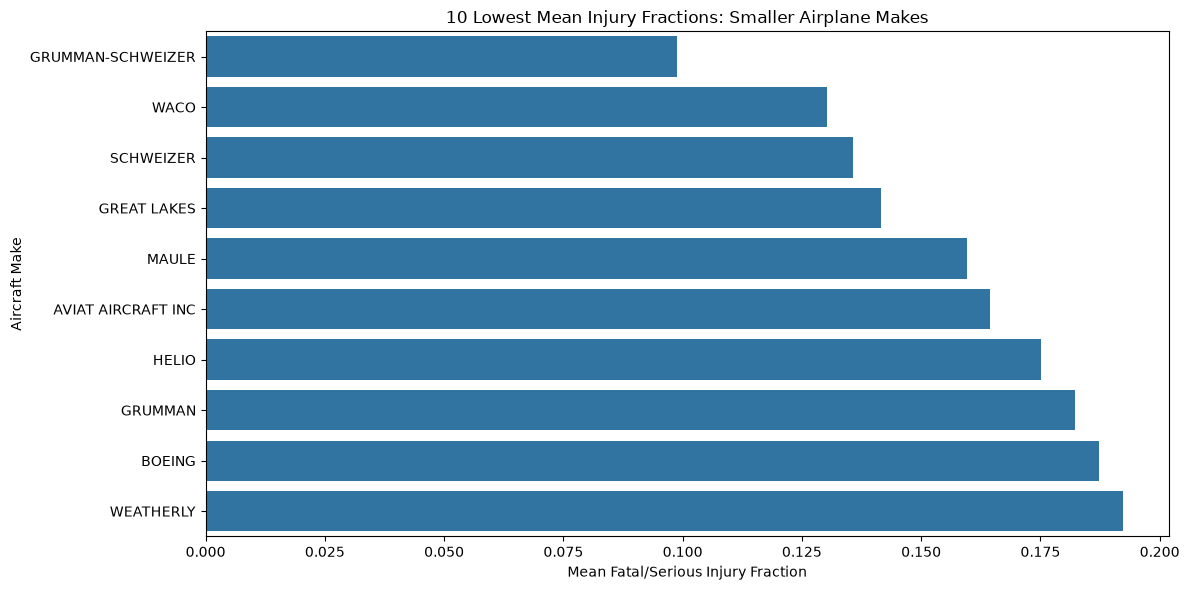

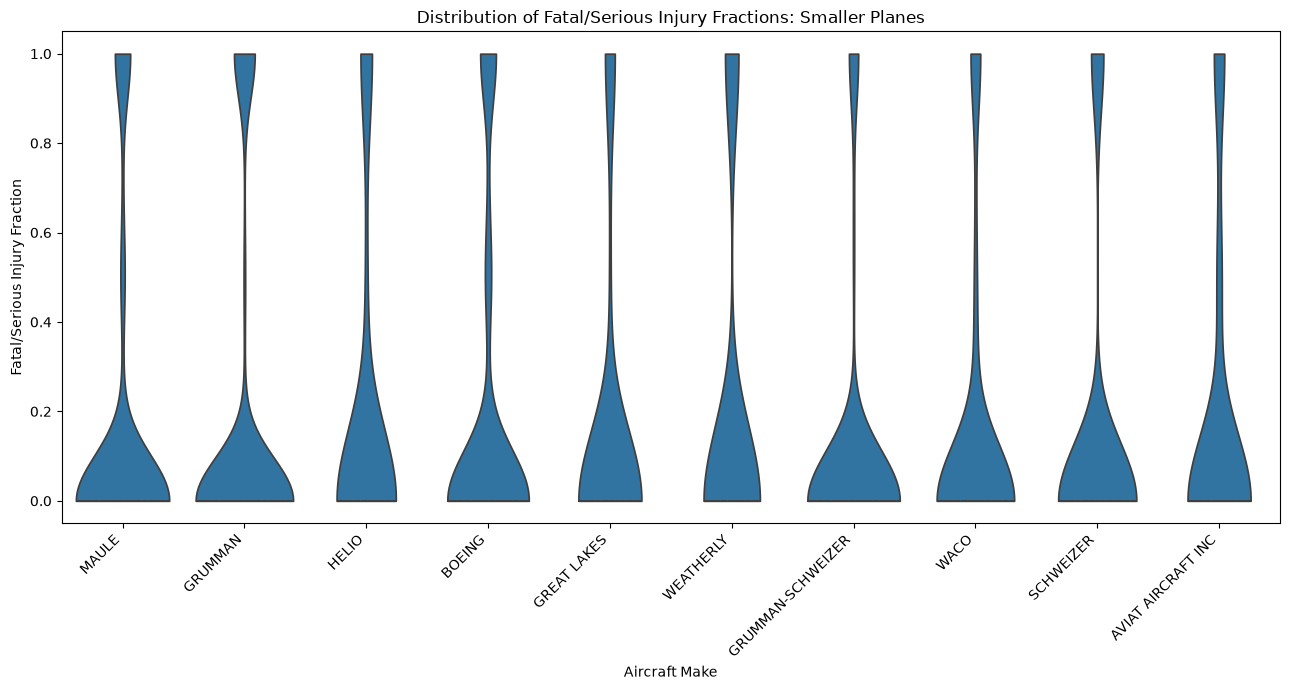

In [ ]:
# Keeping records with valid make and injury fraction
small_valid = small_airplanes.dropna(
    subset=['Make', 'Fatal.Serious.Fraction']
).copy()

# Requiring at least 10 accident records per make
small_make_counts = small_valid['Make'].value_counts()
valid_small_makes = small_make_counts[small_make_counts >= 10].index

small_valid = small_valid[
    small_valid['Make'].isin(valid_small_makes)
].copy()

# Selecting the 10 makes with the lowest mean injury fractions
top_10_small_makes = (
    small_valid.groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .nsmallest(10)
    .index
)

small_top10_data = small_valid[
    small_valid['Make'].isin(top_10_small_makes)
].copy()

print("Selected makes:")
display(
    small_top10_data.groupby('Make')['Fatal.Serious.Fraction']
    .agg(['count', 'mean'])
    .sort_values('mean')
)


import matplotlib.pyplot as plt
import seaborn as sns

# Calculating mean injury fraction for each selected make
small_make_means = (
    small_top10_data.groupby('Make')['Fatal.Serious.Fraction']
    .mean()
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=small_make_means,
    x='Fatal.Serious.Fraction',
    y='Make'
)

plt.title('10 Lowest Mean Injury Fractions: Smaller Airplane Makes')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Aircraft Make')
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 7))

sns.violinplot(
    data=small_top10_data,
    x='Make',
    y='Fatal.Serious.Fraction',
    inner='quartile',
    cut=0
)

plt.title('Distribution of Fatal/Serious Injury Fractions: Smaller Planes')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of Specific Airplane Types

The analysis compared smaller airplanes (20 passengers or fewer) and larger airplanes (more than 20 passengers) using the fraction of passengers who were fatally or seriously injured in recorded accidents.

For **smaller airplane models**, the analysis focused on the 10 makes with the lowest mean fatal/serious injury fractions. Their mean values helped identify makes with comparatively lower injury fractions in the available accident records. The distribution plots also showed how injury outcomes varied between individual accidents, highlighting that a low average does not necessarily mean consistently low injury fractions.

For **larger airplane models**, models with at least 10 accident records were considered to make the comparisons more meaningful. The mean injury fractions and distributional plots helped compare average outcomes and the variation in injury severity across qualifying models.

Overall, the results suggest that aircraft makes and models should be evaluated using both their mean injury fractions and the distributions of their individual accident outcomes. Models with lower mean fractions and relatively consistent outcomes may warrant further investigation. However, these findings describe passenger injury outcomes among recorded accidents rather than the likelihood of an accident occurring.

**Recommendation:** Evaluate smaller and larger airplanes separately, and consider accident counts alongside mean injury fractions before recommending specific models. Further analysis using flight hours, fleet size, and aircraft usage would be needed to assess overall safety more reliably.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,Accident_Records,Mean_Injury_Fraction,Known_Damage_Records,Destroyed_Records,Destruction_Rate
Weather.Condition,,,,,
UNK,569,0.700,569,364,0.64
IMC,4249,0.688,4249,2540,0.598
VMC,47964,0.224,47964,8013,0.167


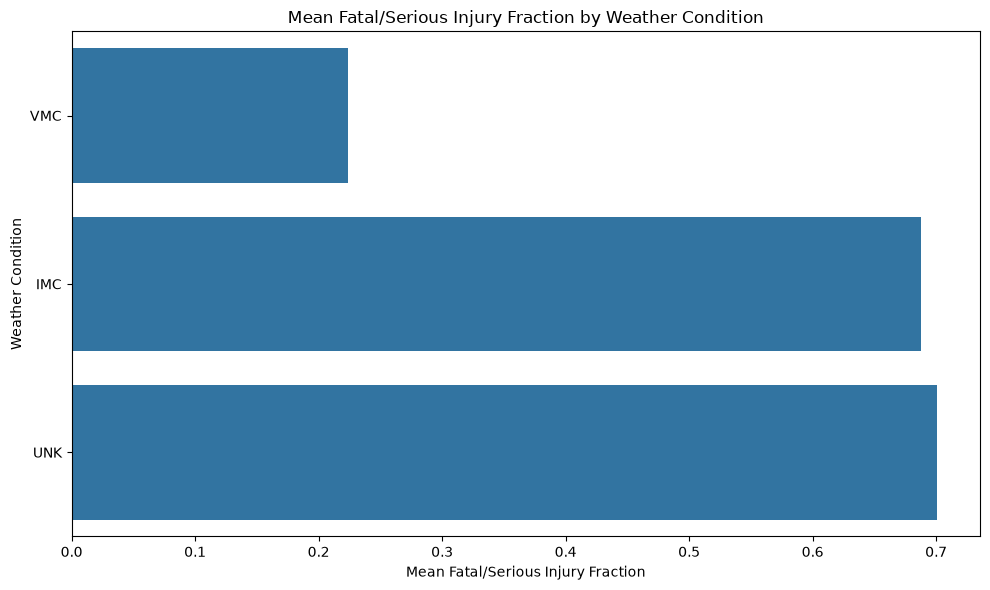

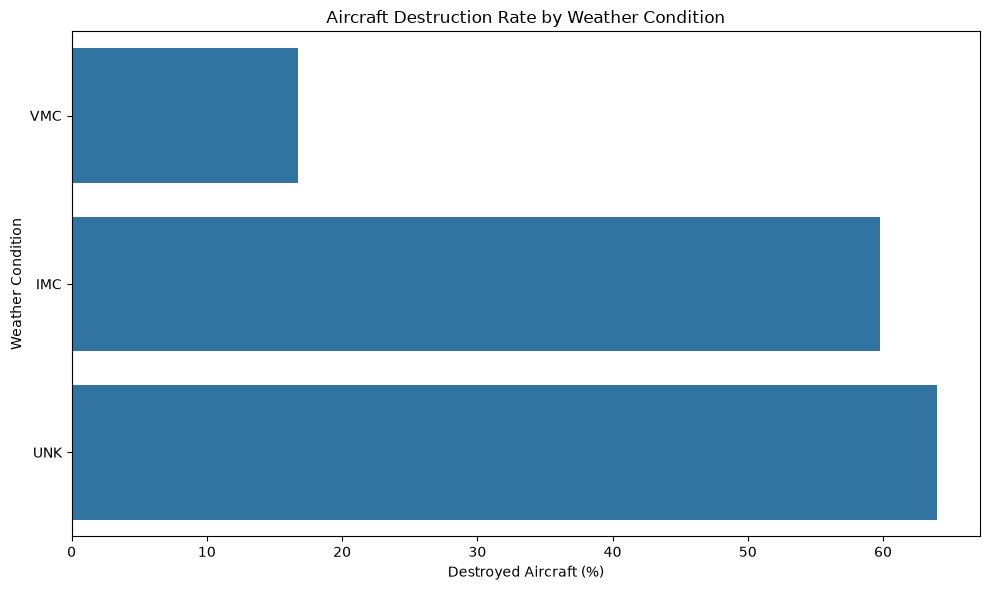

In [ ]:

# Working with the relevant columns without changing the original dataframe
weather_data = df[
    ['Weather.Condition', 'Aircraft.damage', 'Fatal.Serious.Fraction']
].copy()

# Excluding missing weather labels and standardizing their formatting
weather_data['Weather.Condition'] = weather_data['Weather.Condition'].apply(
    lambda value: value.strip().upper()
    if isinstance(value, str) else value
)

weather_data = weather_data.dropna(subset=['Weather.Condition'])

# Identifying whether the aircraft was destroyed
weather_data['Destroyed'] = (
    weather_data['Aircraft.damage']
    .astype('string')
    .str.strip()
    .str.casefold()
    .eq('destroyed')
)

# Calculating injury and destruction statistics by weather condition
weather_summary = weather_data.groupby('Weather.Condition').agg(
    Accident_Records=('Weather.Condition', 'size'),
    Mean_Injury_Fraction=('Fatal.Serious.Fraction', 'mean'),
    Known_Damage_Records=('Aircraft.damage', 'count'),
    Destroyed_Records=('Destroyed', lambda x: x.sum())
)

# Calculating destruction rate only among records with known damage
weather_summary['Destruction_Rate'] = (
    weather_summary['Destroyed_Records']
    / weather_summary['Known_Damage_Records']
)

weather_summary = weather_summary.sort_values(
    'Mean_Injury_Fraction', ascending=False
)

display(weather_summary.round(3))


# Comparing mean injury fractions across weather conditions
weather_injury = (
    weather_data.dropna(subset=['Fatal.Serious.Fraction'])
    .groupby('Weather.Condition')['Fatal.Serious.Fraction']
    .mean()
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=weather_injury,
    x='Fatal.Serious.Fraction',
    y='Weather.Condition'
)

plt.title('Mean Fatal/Serious Injury Fraction by Weather Condition')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Weather Condition')
plt.tight_layout()
plt.show()

# Comparing destruction rates among records with known damage
weather_destruction = (
    weather_data.dropna(subset=['Aircraft.damage'])
    .groupby('Weather.Condition')['Destroyed']
    .mean()
    .mul(100)
    .sort_values()
    .reset_index(name='Destruction_Rate_Percent')
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=weather_destruction,
    x='Destruction_Rate_Percent',
    y='Weather.Condition'
)

plt.title('Aircraft Destruction Rate by Weather Condition')
plt.xlabel('Destroyed Aircraft (%)')
plt.ylabel('Weather Condition')
plt.tight_layout()
plt.show()


In [ ]:
# Selecting the relevant columns
phase_data = df[
    ['Broad.phase.of.flight', 'Aircraft.damage', 'Fatal.Serious.Fraction']
].copy()

# Standardizing phase labels while preserving missing values
phase_data['Broad.phase.of.flight'] = phase_data[
    'Broad.phase.of.flight'
].apply(
    lambda value: value.strip().title()
    if isinstance(value, str) else value
)

# Removing records with no recorded phase
phase_data = phase_data.dropna(subset=['Broad.phase.of.flight'])

# Identifying destroyed aircraft
phase_data['Destroyed'] = (
    phase_data['Aircraft.damage']
    .astype('string')
    .str.strip()
    .str.casefold()
    .eq('destroyed')
)

# Summary injury outcomes and aircraft destruction by phase
phase_summary = phase_data.groupby('Broad.phase.of.flight').agg(
    Accident_Records=('Broad.phase.of.flight', 'size'),
    Mean_Injury_Fraction=('Fatal.Serious.Fraction', 'mean'),
    Known_Damage_Records=('Aircraft.damage', 'count'),
    Destroyed_Records=('Destroyed', 'sum')
)

# Calculating destruction rates 
phase_summary['Destruction_Rate'] = (
    phase_summary['Destroyed_Records']
    / phase_summary['Known_Damage_Records']
)

phase_summary = phase_summary.sort_values(
    'Mean_Injury_Fraction', ascending=False
)

display(phase_summary.round(3))

,Accident_Records,Mean_Injury_Fraction,Known_Damage_Records,Destroyed_Records,Destruction_Rate
Broad.phase.of.flight,,,,,
Unknown,324,0.824,324,244,0.753
Maneuvering,4302,0.525,4302,2017,0.469
Climb,1237,0.447,1237,552,0.446
Other,49,0.406,49,16,0.327
Cruise,6491,0.357,6491,2243,0.346
Approach,4133,0.355,4133,1242,0.301
Descent,1126,0.351,1126,377,0.335
Go-Around,1093,0.297,1093,310,0.284
Takeoff,8075,0.228,8075,1761,0.218


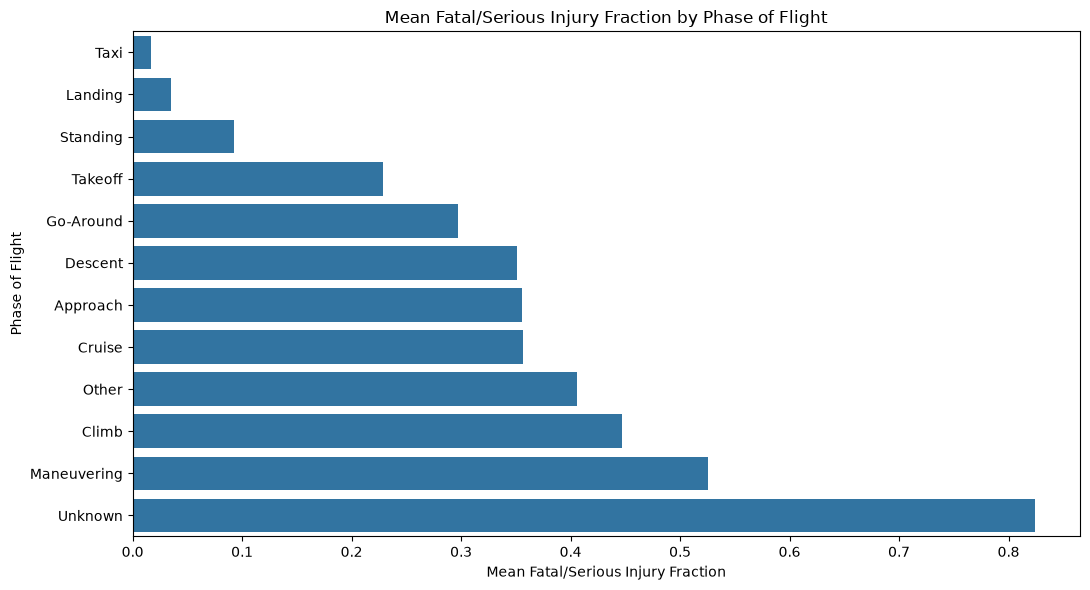

In [29]:
# Calculate the mean injury fraction for each phase
phase_injury = (
    phase_data.dropna(subset=['Fatal.Serious.Fraction'])
    .groupby('Broad.phase.of.flight')['Fatal.Serious.Fraction']
    .mean()
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=phase_injury,
    x='Fatal.Serious.Fraction',
    y='Broad.phase.of.flight'
)

plt.title('Mean Fatal/Serious Injury Fraction by Phase of Flight')
plt.xlabel('Mean Fatal/Serious Injury Fraction')
plt.ylabel('Phase of Flight')
plt.tight_layout()
plt.show()

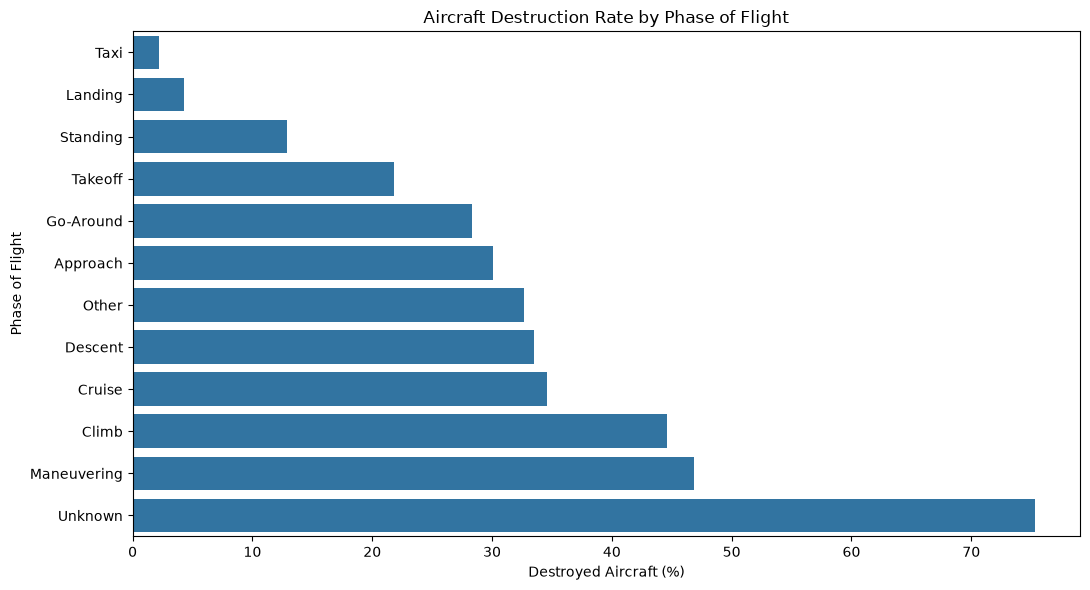

In [ ]:
# Calculating destruction rates for records with known damage
phase_destruction = (
    phase_data.dropna(subset=['Aircraft.damage'])
    .groupby('Broad.phase.of.flight')['Destroyed']
    .mean()
    .mul(100)
    .sort_values()
    .reset_index(name='Destruction_Rate_Percent')
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=phase_destruction,
    x='Destruction_Rate_Percent',
    y='Broad.phase.of.flight'
)

plt.title('Aircraft Destruction Rate by Phase of Flight')
plt.xlabel('Destroyed Aircraft (%)')
plt.ylabel('Phase of Flight')
plt.tight_layout()
plt.show()

#### Discussion: Weather Condition

Weather conditions were compared using the mean fatal/serious injury fraction and the percentage of recorded accidents in which the aircraft was destroyed. The summary table and bar charts help identify differences in injury outcomes and aircraft damage across weather categories.

The weather condition with the highest mean injury fraction had the greatest average proportion of passengers fatally or seriously injured among the recorded accidents in that category. Similarly, differences in destruction rates indicate that the proportion of recorded aircraft destroyed varied across weather categories. These patterns should be interpreted alongside the number of observations in each category, since small samples can produce misleading averages.

#### Discussion: Phase of Flight

The analysis compared injury fractions and aircraft destruction rates across the recorded phases of flight. The mean injury fraction chart highlights phases with comparatively higher or lower average passenger injury fractions, while the destruction-rate chart compares the proportion of aircraft destroyed in each phase.

Differences between phases may help identify where accident outcomes warrant further investigation. However, the results describe accidents in the dataset and do not show the probability of an accident occurring during each phase. Flight exposure, accident circumstances, and the number of records available for each phase should be considered before drawing conclusions.

#### conclusion

Weather condition and phase of flight provide useful perspectives on aircraft damage and passenger injury outcomes. Both factors should be considered alongside accident counts and missing data when interpreting the results. The analysis identifies associations in the recorded accidents, but it does not establish that either factor directly causes more severe outcomes.